# Chapter 13: Error-state MPC and on-manifold solvers

This notebook reproduces the chapter's examples with NumPy and SciPy alone.

1. Newton's method on the sphere and on $\mathrm{SO}(3)$: the step is a vector in the tangent space, the update is a rotation.
2. The error-state model of the rigid body, checked against perturbed nonlinear trajectories.
3. The finite-horizon tracking problem as a QP with box constraints, a small solver for it, and the link to LQR.
4. A flip with too little torque: error-state MPC, a saturated LQR and an Euler-angle MPC.
5. Where the linear model stops being accurate.
6. Direct transcription on $\mathrm{SO}(3)$ and a primal-dual interior point with on-manifold steps.

Notation follows the book: $\dot R = R\,\Omega^\wedge$, the error is $\chi = \log(R_d^\top R)^\vee$, and a step on the group is $R \leftarrow R\exp(\eta^\wedge)$.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")

import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import expm, solve_discrete_are
from scipy.optimize import lsq_linear, minimize

np.set_printoptions(precision=4, suppress=True, linewidth=120)
E1, E2, E3 = np.eye(3)
I3, ZERO3 = np.eye(3), np.zeros(3)
J_B = np.diag([0.03, 0.05, 0.07])              # kg·m², the body of Chapter 7
J_INV = np.linalg.inv(J_B)


def hat(v):
    x, y, z = v
    return np.array([[0.0, -z, y], [z, 0.0, -x], [-y, x, 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    """exp(hat(w)) by Rodrigues' formula."""
    th = np.linalg.norm(w)
    if th < 1e-12:
        return np.eye(3) + hat(w)
    K = hat(w / th)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def log_so3(R):
    """Rotation vector of R (angle below pi)."""
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    if th < 1e-8:
        return vee(R - R.T) / 2
    return th / (2 * np.sin(th)) * vee(R - R.T)


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def random_rotation(rng):
    Q, R = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(R)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q


def unit(v):
    v = np.asarray(v, float)
    return v / np.linalg.norm(v)


def dexp(x):
    th = np.linalg.norm(x)
    X = hat(x)
    if th < 1e-6:
        return I3 - 0.5 * X + X @ X / 6
    return I3 - (1 - np.cos(th)) / th**2 * X + (th - np.sin(th)) / th**3 * X @ X


def dexp_inv(x):
    th = np.linalg.norm(x)
    X = hat(x)
    if th < 1e-6:
        return I3 + 0.5 * X + X @ X / 12
    return I3 + 0.5 * X + (1 / th**2 - (1 + np.cos(th)) / (2 * th * np.sin(th))) * X @ X


def project_so3(M):
    """Nearest rotation in the Frobenius norm."""
    U, _, Vt = np.linalg.svd(M)
    return U @ np.diag([1.0, 1.0, np.linalg.det(U @ Vt)]) @ Vt


def angle_between(q, p):
    """Angle between two unit vectors, accurate for small angles."""
    return float(np.arctan2(np.linalg.norm(np.cross(q, p)), q @ p))

## A step that stays on the sphere

Four readings of a direction, and the point that minimizes the sum of squared angles to them. A move of $q$ is $q \mapsto \exp(\xi^\wedge) q$ with $\xi \cdot q = 0$. The gradient along it is $\sum_i (\theta_i/\sin\theta_i)\, q_i \times q$.

In [2]:
def s2_log(q, p):
    """Tangent vector at q that points to p, with length the angle between them."""
    c = np.clip(q @ p, -1, 1)
    th = np.arccos(c)
    v = p - c * q
    n = np.linalg.norm(v)
    return np.zeros(3) if n < 1e-14 else th * v / n


def s2_mean_cost(q, pts):
    return 0.5 * sum(np.arccos(np.clip(q @ p, -1, 1)) ** 2 for p in pts)


def s2_mean_grad_hess(q, pts):
    """Gradient and Hessian of the cost along q -> exp(xi^) q, with xi in the tangent plane."""
    g, H = np.zeros(3), np.zeros((3, 3))
    for p in pts:
        v = s2_log(q, p)
        th = np.linalg.norm(v)
        g -= np.cross(q, v)
        if th < 1e-9:
            H += I3 - np.outer(q, q)
            continue
        t = v / th                                 # along the great circle to p
        nrm = np.cross(q, t)                       # turning about nrm moves q along it
        H += np.outer(nrm, nrm) + th / np.tan(th) * np.outer(t, t)
    return g, H


def s2_mean_newton(q0, pts, iters=6):
    """Newton iterates q <- exp(xi^) q. Returns the iterates and the steps."""
    q, qs, steps = np.array(q0, float), [np.array(q0, float)], []
    for _ in range(iters):
        g, H = s2_mean_grad_hess(q, pts)
        xi = -np.linalg.solve(H + np.outer(q, q), g)   # the q q^T block fixes the unused direction
        xi -= (xi @ q) * q
        q = expm_so3(xi) @ q
        qs.append(q)
        steps.append(xi)
    return np.array(qs), np.array(steps)


pts = [unit(v) for v in ([0.95, 0.05, 0.31], [0.25, 0.80, 0.55], [0.35, -0.45, 0.82], [0.70, 0.45, 0.55])]
print("length of the plain average:", np.linalg.norm(sum(pts) / 4).round(3))
qs, steps = s2_mean_newton(pts[0], pts, 5)
for k, q in enumerate(qs[:4]):
    print(f"iteration {k}: |q| - 1 = {np.linalg.norm(q) - 1:+.1e}, "
          f"distance to the mean {np.degrees(angle_between(q, qs[-1])):.2e} deg")

length of the plain average: 0.82
iteration 0: |q| - 1 = -1.1e-16, distance to the mean 2.94e+01 deg
iteration 1: |q| - 1 = -1.1e-16, distance to the mean 4.12e-01 deg
iteration 2: |q| - 1 = -2.2e-16, distance to the mean 3.17e-05 deg
iteration 3: |q| - 1 = -2.2e-16, distance to the mean 2.00e-13 deg


The same on $\mathrm{SO}(3)$. The cost is $\Phi(R) = \tfrac12\sum_i\|\chi_i\|^2$ with $\chi_i = \log(R_i^\top R)^\vee$. Its gradient along $R\exp(\eta^\wedge)$ is $\sum_i \chi_i$ and its Hessian is $\sum_i [\tfrac{\theta_i}{2}\cot\tfrac{\theta_i}{2}\, I + (1 - \tfrac{\theta_i}{2}\cot\tfrac{\theta_i}{2})\, a_i a_i^\top]$.

determinant of the entrywise average: 0.083
gradient error: 2.537419163672894e-10  Hessian error: 1.1302870861484848e-07


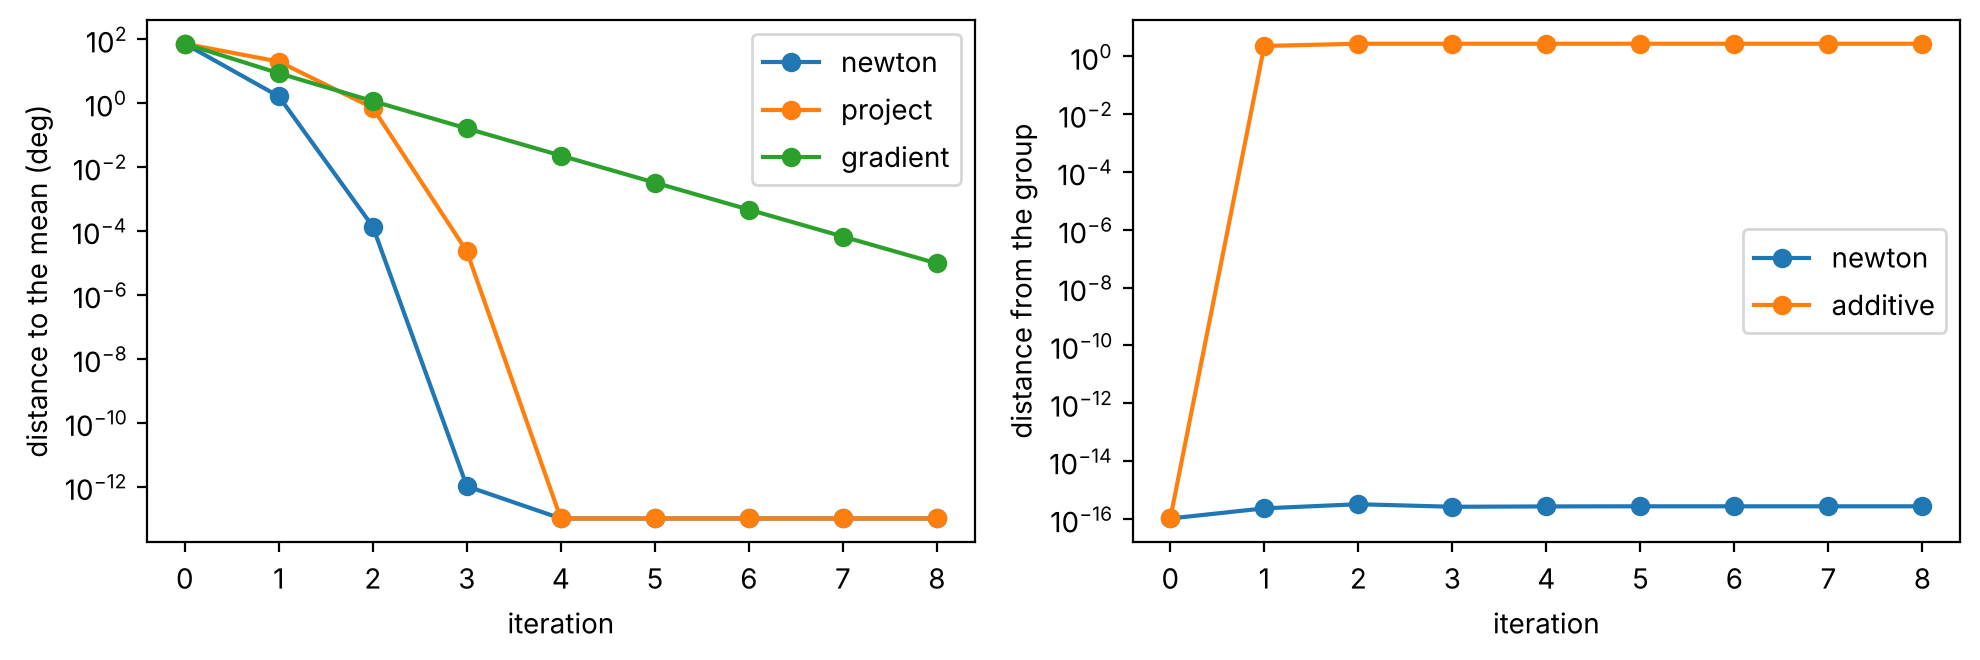

In [3]:
def so3_mean_cost(R, Rs):
    return 0.5 * sum(np.linalg.norm(log_so3(Ri.T @ R)) ** 2 for Ri in Rs)


def so3_mean_grad(R, Rs):
    """Gradient along R -> R exp(eta^): the sum of the logarithm errors."""
    return sum(log_so3(Ri.T @ R) for Ri in Rs)


def so3_mean_hess(R, Rs):
    H = np.zeros((3, 3))
    for Ri in Rs:
        chi = log_so3(Ri.T @ R)
        th = np.linalg.norm(chi)
        if th < 1e-9:
            H += I3
            continue
        a, k = chi / th, 0.5 * th / np.tan(0.5 * th)
        H += k * I3 + (1 - k) * np.outer(a, a)
    return H


def so3_mean_iterate(R0, Rs, method="newton", iters=8):
    """Iterates of four ways to use the same tangent-space information.

    newton    : eta = -H^-1 g,  R <- R exp(eta^)          (exponential retraction)
    project   : eta = -H^-1 g,  R <- project(R + R eta^)  (projection retraction)
    gradient  : eta = -g / n,   R <- R exp(eta^)
    additive  : eta = -H^-1 g,  R <- R + R eta^           (leaves the group)
    """
    R, out = np.array(R0, float), [np.array(R0, float)]
    for _ in range(iters):
        Rp = project_so3(R) if method == "additive" else R   # the cost needs a rotation
        g = so3_mean_grad(Rp, Rs)
        eta = -g / len(Rs) if method == "gradient" else -np.linalg.solve(so3_mean_hess(Rp, Rs), g)
        if method in ("newton", "gradient"):
            R = R @ expm_so3(eta)
        elif method == "project":
            R = project_so3(R + R @ hat(eta))
        else:
            R = R + R @ hat(eta)
        out.append(R)
    return out


Rc = Rz(0.4) @ Ry(1.1) @ Rx(-0.3)
spread = ((0, [1, 0, 0]), (133, [1, 0.2, 0]), (98, [0, 1, 0.3]), (84, [-0.3, 0.2, 1]), (140, [0.6, 0.7, -0.2]))
Rs = [Rc @ expm_so3(np.radians(a) * unit(v)) for a, v in spread]
print("determinant of the entrywise average:", np.linalg.det(sum(Rs) / 5).round(3))

# check the gradient and the Hessian by finite differences of the cost
R = Rs[0] @ expm_so3(np.array([0.3, -0.2, 0.1]))
f = lambda eta: so3_mean_cost(R @ expm_so3(eta), Rs)
e = 1e-4
g_fd = np.array([(f(e * d) - f(-e * d)) / (2 * e) for d in I3])
H_fd = np.array([[(f(e * a + e * b) - f(e * a - e * b) - f(-e * a + e * b) + f(-e * a - e * b)) / (4 * e * e)
                  for b in I3] for a in I3])
print("gradient error:", np.abs(g_fd - so3_mean_grad(R, Rs)).max(), " Hessian error:", np.abs(H_fd - so3_mean_hess(R, Rs)).max())

R_mean = so3_mean_iterate(Rs[0], Rs, "newton", 12)[-1]
dist = lambda Rk: np.degrees(np.linalg.norm(log_so3(R_mean.T @ project_so3(Rk))))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for name in ("newton", "project", "gradient"):
    ax[0].semilogy([max(dist(Rk), 1e-13) for Rk in so3_mean_iterate(Rs[0], Rs, name, 8)], "-o", label=name)
for name in ("newton", "additive"):
    ax[1].semilogy([max(np.linalg.norm(Rk.T @ Rk - I3), 1e-16) for Rk in so3_mean_iterate(Rs[0], Rs, name, 8)], "-o", label=name)
ax[0].set(xlabel="iteration", ylabel="distance to the mean (deg)")
ax[1].set(xlabel="iteration", ylabel="distance from the group")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## The error is the variable

The error state is $s = (\chi, \delta\Omega)$ with $\chi = \log(R_d^\top R)^\vee$ and $\delta\Omega = \Omega - \Omega_d$. To first order

$$\dot\chi = -\Omega_d \times \chi + \delta\Omega, \qquad J\,\delta\dot\Omega = \big((J\Omega_d)^\wedge - \Omega_d^\wedge J\big)\,\delta\Omega + \delta\tau .$$

The reference attitude does not appear. We check the model against centered differences of two perturbed nonlinear trajectories, and the exact formula $\dot\chi = \operatorname{dexp}_\chi^{-1}(\Omega - \exp(-\chi^\wedge)\Omega_d)$ against a numerical derivative.

In [4]:
def err_A(Od, J=J_B):
    A = np.zeros((6, 6))
    A[:3, :3] = -hat(Od)
    A[:3, 3:] = I3
    A[3:, 3:] = np.linalg.solve(J, hat(J @ Od) - hat(Od) @ J)
    return A


ERR_B = np.vstack([np.zeros((3, 3)), J_INV])


def chi_dot_exact(chi, Om, Od):
    """Exact rate of the logarithm of the left-invariant error on SO(3)."""
    return dexp_inv(chi) @ (Om - expm_so3(-chi) @ Od)


def fly(R0, O0, tau_fun, T=1.0):
    """The nonlinear rigid body J Omega_dot + Omega x J Omega = tau."""
    def rhs(t, y):
        Rm, w = y[:9].reshape(3, 3), y[9:]
        return np.r_[(Rm @ hat(w)).ravel(), J_INV @ (np.cross(J_B @ w, w) + tau_fun(t))]
    return solve_ivp(rhs, [0, T], np.r_[R0.ravel(), O0], rtol=1e-12, atol=1e-14, method="DOP853", dense_output=True)


rng = np.random.default_rng(13)
tau_ref = lambda t: np.array([0.4 * np.sin(3 * t), 0.5 * np.cos(2 * t), 0.3 * np.sin(4 * t + 1.0)])
dtau = lambda t: np.array([np.cos(5 * t), -0.5, np.sin(3 * t)])
Rd0, Od0 = random_rotation(rng), np.array([2.0, -3.0, 1.5])
base = fly(Rd0, Od0, tau_ref)
chi0, dO0 = rng.normal(size=3), rng.normal(size=3)
lin = solve_ivp(lambda t, s: err_A(base.sol(t)[9:]) @ s + ERR_B @ dtau(t), [0, 1.0], np.r_[chi0, dO0],
                rtol=1e-12, atol=1e-14, dense_output=True)
for eps in (1e-3, 1e-4):
    up = fly(Rd0 @ expm_so3(eps * chi0), Od0 + eps * dO0, lambda t: tau_ref(t) + eps * dtau(t))
    dn = fly(Rd0 @ expm_so3(-eps * chi0), Od0 - eps * dO0, lambda t: tau_ref(t) - eps * dtau(t))
    gap = 0.0
    for t in np.linspace(0, 1, 21):
        Rb = base.sol(t)[:9].reshape(3, 3)
        s_fd = np.r_[log_so3(Rb.T @ up.sol(t)[:9].reshape(3, 3)) - log_so3(Rb.T @ dn.sol(t)[:9].reshape(3, 3)),
                     up.sol(t)[9:] - dn.sol(t)[9:]] / (2 * eps)
        gap = max(gap, np.abs(s_fd - lin.sol(t)).max())
    print(f"eps = {eps:g}: linear model against perturbed trajectories, mismatch {gap:.1e}")

big = fly(Rd0 @ expm_so3(np.array([0.5, -0.7, 0.4])), Od0 + np.array([0.3, 0.2, -0.5]), tau_ref)
chi_at = lambda t: log_so3(base.sol(t)[:9].reshape(3, 3).T @ big.sol(t)[:9].reshape(3, 3))
t1, e = 0.37, 1e-5
print("exact error dynamics, mismatch:",
      np.abs((chi_at(t1 + e) - chi_at(t1 - e)) / (2 * e) - chi_dot_exact(chi_at(t1), big.sol(t1)[9:], base.sol(t1)[9:])).max())

eps = 0.001: linear model against perturbed trajectories, mismatch 6.5e-05
eps = 0.0001: linear model against perturbed trajectories, mismatch 6.5e-07
exact error dynamics, mismatch: 3.968475770221858e-09


## A quadratic program

Sample the model, $s_{k+1} = A_k s_k + B_k\,\delta\tau_k$, eliminate the states and stack the corrections in $U$. The tracking problem becomes

$$\min_U\ \tfrac12 U^\top H\,U + (F s_0)\cdot U, \qquad U_{\min} \le U \le U_{\max}.$$

`box_qp` is a projected Newton method. We compare it with SciPy's bounded least squares and check that MPC without bounds is LQR.

In [5]:
H_MPC, N_MPC = 0.02, 25
Q_MPC = np.diag([100.0] * 3 + [1.0] * 3)
RU_MPC = 20.0 * np.eye(3)
TAU_MAX = 0.6


def zoh(A, B, h):
    """Exact sampling of s' = A s + B u with u held over a step of length h."""
    n, m = B.shape
    blk = np.zeros((n + m, n + m))
    blk[:n, :n], blk[:n, n:] = A, B
    E = expm(blk * h)
    return E[:n, :n], E[:n, n:]


def terminal_weight(h=H_MPC, Q=Q_MPC, Ru=RU_MPC):
    """Riccati solution and gain of the sampled regulator for a reference at rest."""
    A, B = zoh(err_A(ZERO3), ERR_B, h)
    P = solve_discrete_are(A, B, h * Q, h * Ru)
    K = np.linalg.solve(h * Ru + B.T @ P @ B, B.T @ P @ A)
    return P, K


def condense(As, Bs, Q, Ru, Pf):
    """Stack s_1..s_N = Sx s_0 + Su U and return the QP data  1/2 U^T H U + (F s_0) . U.

    Stage cost 1/2 s_k^T Q s_k for k = 1..N-1, terminal 1/2 s_N^T Pf s_N, input 1/2 du_k^T Ru du_k.
    """
    N, (n, m) = len(As), Bs[0].shape
    Sx, Su = np.zeros((N * n, n)), np.zeros((N * n, N * m))
    Phi = np.eye(n)
    for k in range(N):
        if k > 0:
            Su[k * n:(k + 1) * n] = As[k] @ Su[(k - 1) * n:k * n]
        Su[k * n:(k + 1) * n, k * m:(k + 1) * m] = Bs[k]
        Phi = As[k] @ Phi
        Sx[k * n:(k + 1) * n] = Phi
    Qbar = np.kron(np.eye(N), Q)
    Qbar[-n:, -n:] = Pf
    H = Su.T @ Qbar @ Su + np.kron(np.eye(N), Ru)
    F = Su.T @ Qbar @ Sx
    return 0.5 * (H + H.T), F, Sx, Su


def box_qp(H, p, lo, hi, U0=None, tol=1e-10, max_iter=200):
    """Minimize 1/2 U^T H U + p . U subject to lo <= U <= hi by projected Newton.

    Inputs that sit on a bound and want to push through it are held. A Newton step is
    taken in the others, then clipped to the bounds, with a backtracking line search.
    Returns U and the number of iterations.
    """
    U = np.clip(np.zeros_like(p) if U0 is None else U0, lo, hi)
    for it in range(max_iter):
        g = H @ U + p
        act = ((U <= lo + 1e-12) & (g > 0)) | ((U >= hi - 1e-12) & (g < 0))
        res = np.where(act, 0.0, g)
        inner = ~act & (U > lo + 1e-12) & (U < hi - 1e-12)
        if np.max(np.abs(np.where(inner, g, 0.0)), initial=0.0) <= tol and \
                np.max(np.abs(np.clip(U - res, lo, hi) - U)) <= tol:
            return U, it
        d = np.zeros_like(U)
        free = ~act
        d[free] = -np.linalg.solve(H[np.ix_(free, free)], g[free])
        f0, a = 0.5 * U @ H @ U + p @ U, 1.0
        while True:
            Un = np.clip(U + a * d, lo, hi)
            if 0.5 * Un @ H @ Un + p @ Un <= f0 + 1e-4 * g @ (Un - U) or a < 1e-10:
                break
            a *= 0.5
        U = Un
    return U, max_iter


def box_qp_kkt(H, p, lo, hi, U):
    """Largest violation of the optimality conditions of the box-constrained QP."""
    g = H @ U + p
    at_lo, at_hi = U <= lo + 1e-9, U >= hi - 1e-9
    stat = np.where(at_lo, np.minimum(g, 0), np.where(at_hi, np.maximum(g, 0), g))
    feas = max(np.max(lo - U), np.max(U - hi), 0.0)
    return float(max(np.max(np.abs(stat)), feas))


def box_qp_reference(H, p, lo, hi):
    """The same QP solved by SciPy's bounded-variable least squares (an active-set method)."""
    L = np.linalg.cholesky(H)
    sol = lsq_linear(L.T, -np.linalg.solve(L, p), bounds=(lo, hi), method="bvls", tol=1e-14, max_iter=2000)
    return sol.x


class Turn:
    """Rest-to-rest turn by `angle` about a fixed body axis in time T, then hold.

    Turn(2 pi, axis tilted 5 deg from e2, 1.5) is the flip of Chapter 7.
    """

    def __init__(self, angle, axis, T):
        self.total, self.n, self.T = angle, unit(axis), T

    def __call__(self, t):
        s = np.clip(t / self.T, 0.0, 1.0)
        a = self.total * (10 * s**3 - 15 * s**4 + 6 * s**5)
        da = self.total * (30 * s**2 - 60 * s**3 + 30 * s**4) / self.T
        dda = self.total * (60 * s - 180 * s**2 + 120 * s**3) / self.T**2
        Od = da * self.n
        return expm_so3(a * self.n), Od, J_B @ (dda * self.n) + np.cross(Od, J_B @ Od)


def flip_ref():
    d = np.radians(5.0)
    return Turn(2 * np.pi, [np.sin(d), np.cos(d), 0.0], 1.5)


ref = flip_ref()
Pf, K_rest = terminal_weight()
k0 = 20
AB = [zoh(err_A(ref((k0 + i + 0.5) * H_MPC)[1]), ERR_B, H_MPC) for i in range(N_MPC)]
H, F, Sx, Su = condense([a for a, _ in AB], [b for _, b in AB], H_MPC * Q_MPC, H_MPC * RU_MPC, Pf)
print("H is positive definite, eigenvalues in", np.linalg.eigvalsh(H)[[0, -1]].round(3))
ff = np.array([ref((k0 + i + 0.5) * H_MPC)[2] for i in range(N_MPC)]).ravel()
s0 = np.r_[np.radians(50) * unit([1, -1, 0.5]), 1.0, -2.0, 0.5]
U, iters = box_qp(H, F @ s0, -TAU_MAX - ff, TAU_MAX - ff)
U_ref = box_qp_reference(H, F @ s0, -TAU_MAX - ff, TAU_MAX - ff)
print(f"projected Newton: {iters} iterations, difference from SciPy {np.abs(U - U_ref).max():.1e}, "
      f"optimality residual {box_qp_kkt(H, F @ s0, -TAU_MAX - ff, TAU_MAX - ff, U):.1e}")

A0, B0 = zoh(err_A(ZERO3), ERR_B, H_MPC)
for N in (1, 5, 25):
    Hn, Fn, _, _ = condense([A0] * N, [B0] * N, H_MPC * Q_MPC, H_MPC * RU_MPC, Pf)
    print(f"N = {N:2d}: first move of unconstrained MPC minus the LQR gain: {np.abs(np.linalg.solve(Hn, Fn)[:3] - K_rest).max():.1e}")

H is positive definite, eigenvalues in [ 0.4   51.959]
projected Newton: 5 iterations, difference from SciPy 8.8e-15, optimality residual 2.7e-15
N =  1: first move of unconstrained MPC minus the LQR gain: 0.0e+00
N =  5: first move of unconstrained MPC minus the LQR gain: 1.8e-15
N = 25: first move of unconstrained MPC minus the LQR gain: 4.9e-15


## A flip with too little torque

The flip of Chapter 7 asks for 0.80 N·m. The motors give 0.6. Three controllers: error-state MPC, the sampled LQR with its torque clipped afterwards, and the same MPC written in yaw, pitch and roll.

error-state MPC  worst error after 0.5 s   5.9 deg, at the end 0.04 deg, largest torque 0.600 N·m
saturated LQR    worst error after 0.5 s  46.3 deg, at the end 1.75 deg, largest torque 0.600 N·m
Euler-angle MPC  worst error after 0.5 s  10.7 deg, at the end 0.19 deg, largest torque 0.600 N·m


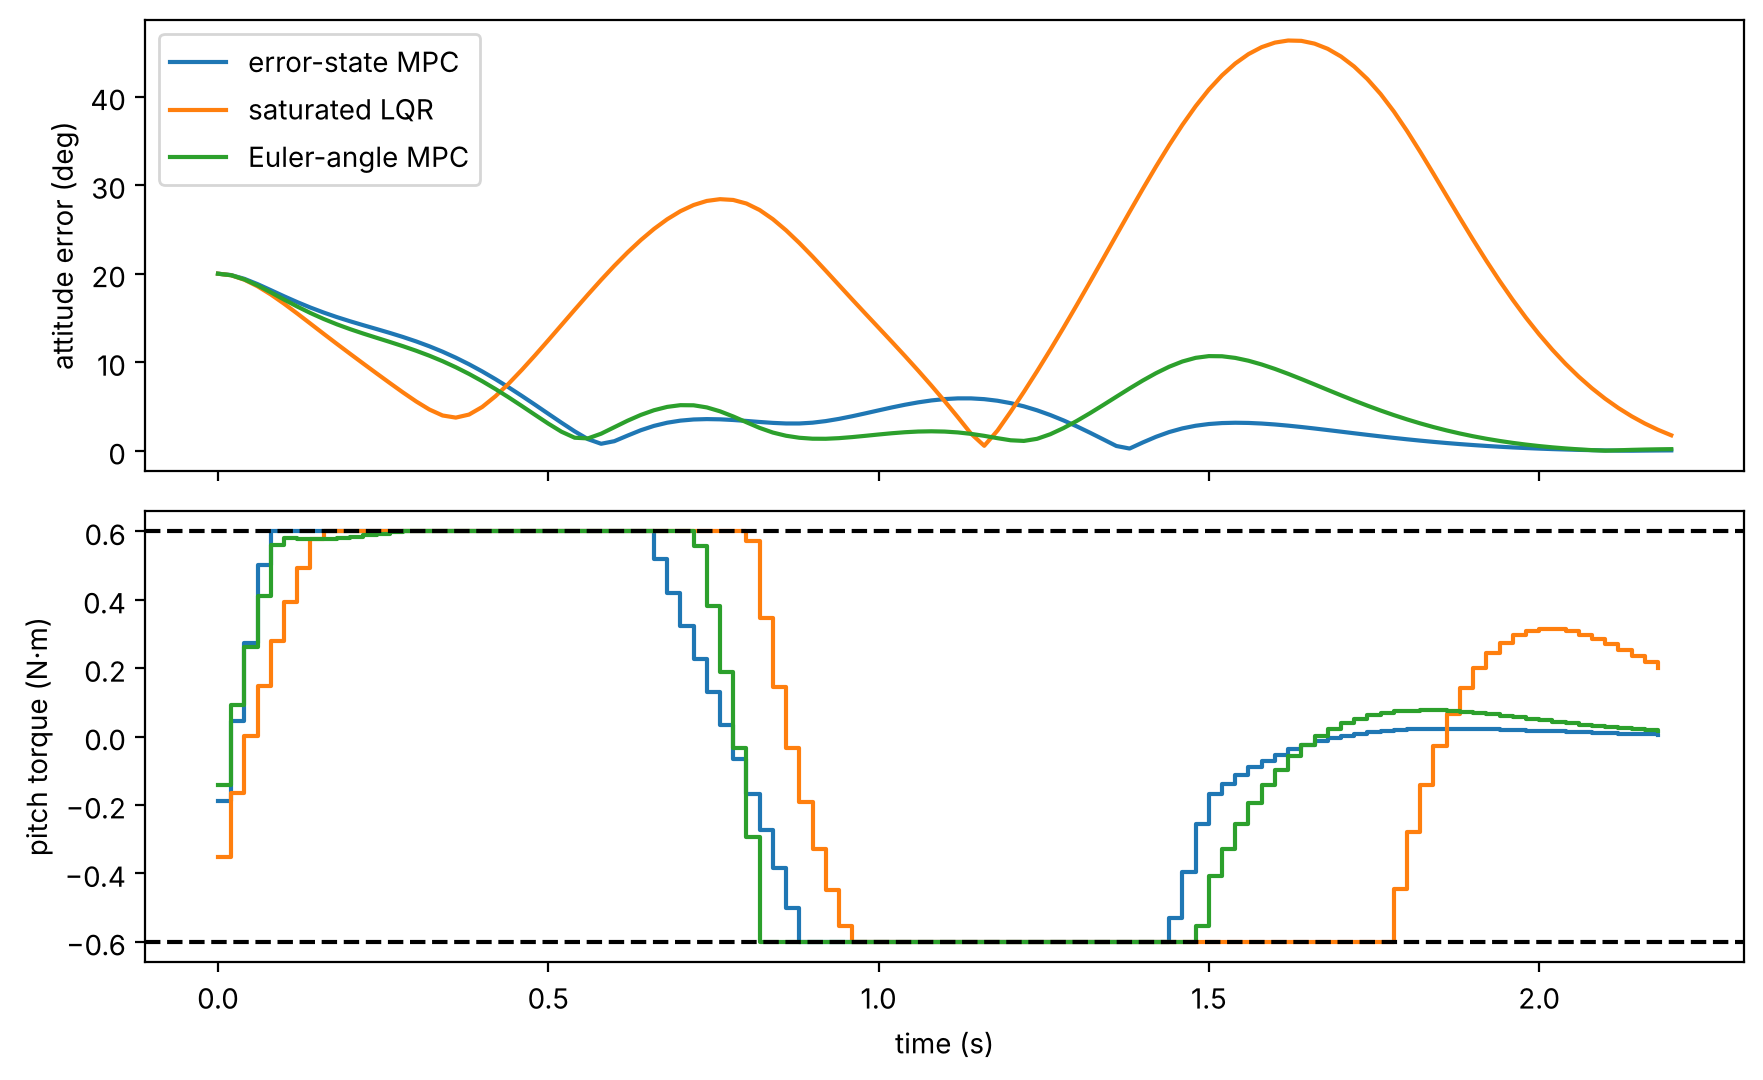

In [6]:
def euler_of(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(np.clip(R[2, 0], -1, 1)),
                     np.arctan2(R[2, 1], R[2, 2])])


def euler_E(th, ph):
    return np.array([[-np.sin(th), 0, 1],
                     [np.cos(th) * np.sin(ph), np.cos(ph), 0],
                     [np.cos(th) * np.cos(ph), -np.sin(ph), 0]])


def euler_f(x, tau):
    eul, Om = x[:3], x[3:]
    return np.r_[np.linalg.solve(euler_E(eul[1], eul[2]), Om), J_INV @ (np.cross(J_B @ Om, Om) + tau)]


def euler_A(x, tau, h=1e-6):
    """Jacobian of the Euler-chart dynamics with respect to (angles, Omega)."""
    A = np.zeros((6, 6))
    for i in range(6):
        d = np.zeros(6)
        d[i] = h
        A[:, i] = (euler_f(x + d, tau) - euler_f(x - d, tau)) / (2 * h)
    return A


def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


class ErrorStateMPC:
    """Error-state MPC along a reference. The QP matrices are tabulated before the flight."""

    def __init__(self, ref, T_end, h=H_MPC, N=N_MPC, Q=Q_MPC, Ru=RU_MPC, tau_max=TAU_MAX, bounded=True):
        self.ref, self.h, self.N, self.tau_max, self.bounded = ref, h, N, tau_max, bounded
        self.Pf, self.K_rest = terminal_weight(h, Q, Ru)
        self.Qh, self.Rh = h * Q, h * Ru
        n_steps = int(round(T_end / h))
        self.AB = [zoh(err_A(ref(k * h + 0.5 * h)[1]), ERR_B, h) for k in range(n_steps + N)]
        self.tau_d = np.array([ref(k * h + 0.5 * h)[2] for k in range(n_steps + N)])
        self.qp = {}
        self.U_prev = None
        self.iters, self.times = [], []

    def data(self, k):
        if k not in self.qp:
            As = [self.AB[k + i][0] for i in range(self.N)]
            Bs = [self.AB[k + i][1] for i in range(self.N)]
            self.qp[k] = condense(As, Bs, self.Qh, self.Rh, self.Pf)[:2]
        return self.qp[k]

    def error_state(self, k, R, Om):
        Rd, Od, _ = self.ref(k * self.h)
        return np.r_[log_so3(Rd.T @ R), Om - Od]

    def __call__(self, k, R, Om):
        H, F = self.data(k)
        s0 = self.error_state(k, R, Om)
        ff = self.tau_d[k:k + self.N].ravel()
        t0 = time.perf_counter()
        if self.bounded:
            warm = None if self.U_prev is None else np.r_[self.U_prev[3:], np.zeros(3)]
            U, it = box_qp(H, F @ s0, -self.tau_max - ff, self.tau_max - ff, warm)
        else:
            U, it = -np.linalg.solve(H, F @ s0), 1
        self.times.append(time.perf_counter() - t0)
        self.iters.append(it)
        self.U_prev = U
        return ff[:3] + U[:3]


class SaturatedLQR:
    """The regulator of Chapter 7 in sampled form, with the torque clipped afterwards."""

    def __init__(self, ref, T_end, h=H_MPC, Q=Q_MPC, Ru=RU_MPC, tau_max=TAU_MAX):
        self.ref, self.h, self.tau_max = ref, h, tau_max
        P, _ = terminal_weight(h, Q, Ru)
        n_steps = int(round(T_end / h)) + N_MPC
        self.K = [None] * n_steps
        for k in reversed(range(n_steps)):
            A, B = zoh(err_A(ref(k * h + 0.5 * h)[1]), ERR_B, h)
            self.K[k] = np.linalg.solve(h * Ru + B.T @ P @ B, B.T @ P @ A)
            P = h * Q + A.T @ P @ (A - B @ self.K[k])
        self.P0 = P

    def __call__(self, k, R, Om):
        Rd, Od, _ = self.ref(k * self.h)
        tau_d = self.ref(k * self.h + 0.5 * self.h)[2]
        tau = tau_d - self.K[k] @ np.r_[log_so3(Rd.T @ R), Om - Od]
        return np.clip(tau, -self.tau_max, self.tau_max)


def euler_ref(ref, ts):
    eul = np.array([euler_of(ref(t)[0]) for t in ts])
    eul[:, 0], eul[:, 2] = np.unwrap(eul[:, 0]), np.unwrap(eul[:, 2])
    return eul


class EulerMPC:
    """The same QP, written in yaw, pitch and roll. Its matrices depend on the reference attitude."""

    def __init__(self, ref, T_end, h=H_MPC, N=N_MPC, Q=Q_MPC, Ru=RU_MPC, tau_max=TAU_MAX):
        self.ref, self.h, self.N, self.tau_max = ref, h, N, tau_max
        self.Pf, _ = terminal_weight(h, Q, Ru)
        self.Qh, self.Rh = h * Q, h * Ru
        n_steps = int(round(T_end / h))
        tm = (np.arange(n_steps + N) + 0.5) * h
        eul_m = euler_ref(ref, np.r_[0.0, tm])[1:]
        self.eul_k = euler_ref(ref, np.arange(n_steps + N + 1) * h)
        self.A_cont = [euler_A(np.r_[e, ref(t)[1]], ref(t)[2]) for e, t in zip(eul_m, tm)]
        self.AB = [zoh(A, ERR_B, h) for A in self.A_cont]
        self.tau_d = np.array([ref(t)[2] for t in tm])
        self.U_prev = None
        self.iters, self.times = [], []

    def __call__(self, k, R, Om):
        As = [self.AB[k + i][0] for i in range(self.N)]
        Bs = [self.AB[k + i][1] for i in range(self.N)]
        H, F = condense(As, Bs, self.Qh, self.Rh, self.Pf)[:2]
        s0 = np.r_[wrap(euler_of(R) - self.eul_k[k]), Om - self.ref(k * self.h)[1]]
        ff = self.tau_d[k:k + self.N].ravel()
        t0 = time.perf_counter()
        warm = None if self.U_prev is None else np.r_[self.U_prev[3:], np.zeros(3)]
        U, it = box_qp(H, F @ s0, -self.tau_max - ff, self.tau_max - ff, warm)
        self.times.append(time.perf_counter() - t0)
        self.iters.append(it)
        self.U_prev = U
        return ff[:3] + U[:3]


def plant_step(R, Om, tau, h, J=J_B):
    """The nonlinear rigid body over one sampling period with the torque held."""
    def rhs(t, y):
        Rm, w = y[:9].reshape(3, 3), y[9:]
        return np.r_[(Rm @ hat(w)).ravel(), np.linalg.solve(J, np.cross(J @ w, w) + tau)]

    y = solve_ivp(rhs, [0, h], np.r_[R.ravel(), Om], rtol=1e-10, atol=1e-12, method="DOP853").y[:, -1]
    return project_so3(y[:9].reshape(3, 3)), y[9:]


def closed_loop(ctrl, ref, R0, Om0, T_end, h=H_MPC):
    """Run a sampled controller on the nonlinear plant. Returns times, attitudes, torques, error angles."""
    n = int(round(T_end / h))
    R, Om = np.array(R0, float), np.array(Om0, float)
    Rs, Oms, taus, ang = [R], [Om], [], [np.degrees(np.linalg.norm(log_so3(ref(0.0)[0].T @ R)))]
    for k in range(n):
        tau = ctrl(k, R, Om)
        R, Om = plant_step(R, Om, tau, h)
        Rs.append(R)
        Oms.append(Om)
        taus.append(tau)
        ang.append(np.degrees(np.linalg.norm(log_so3(ref((k + 1) * h)[0].T @ R))))
    return dict(t=np.arange(n + 1) * h, R=np.array(Rs), Om=np.array(Oms), tau=np.array(taus), angle=np.array(ang))


R0 = ref(0.0)[0] @ expm_so3(np.radians(20.0) * unit([1.0, 1.0, 1.0]))
T_end = 2.2
runs = {"error-state MPC": closed_loop(ErrorStateMPC(ref, T_end, tau_max=TAU_MAX), ref, R0, ZERO3, T_end),
        "saturated LQR": closed_loop(SaturatedLQR(ref, T_end, tau_max=TAU_MAX), ref, R0, ZERO3, T_end),
        "Euler-angle MPC": closed_loop(EulerMPC(ref, T_end, tau_max=TAU_MAX), ref, R0, ZERO3, T_end)}
fig, ax = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
for name, r in runs.items():
    ax[0].plot(r["t"], r["angle"], label=name)
    ax[1].step(r["t"][:-1], r["tau"][:, 1], where="post", label=name)
    print(f"{name:16s} worst error after 0.5 s {r['angle'][25:].max():5.1f} deg, at the end {r['angle'][-1]:.2f} deg, "
          f"largest torque {np.abs(r['tau']).max():.3f} N·m")
ax[1].axhline(TAU_MAX, color="k", ls="--"); ax[1].axhline(-TAU_MAX, color="k", ls="--")
ax[0].set_ylabel("attitude error (deg)"); ax[1].set_ylabel("pitch torque (N·m)"); ax[1].set_xlabel("time (s)")
ax[0].legend(); plt.tight_layout(); plt.show()

Now hold a nose-up attitude at 85° of pitch from a 20° error, with the same bound. The Euler-angle model is close to its singularity for the whole run.

error-state MPC  peak error   20.0 deg, after 3 s   0.00 deg


Euler-angle MPC  peak error  177.3 deg, after 3 s  75.63 deg


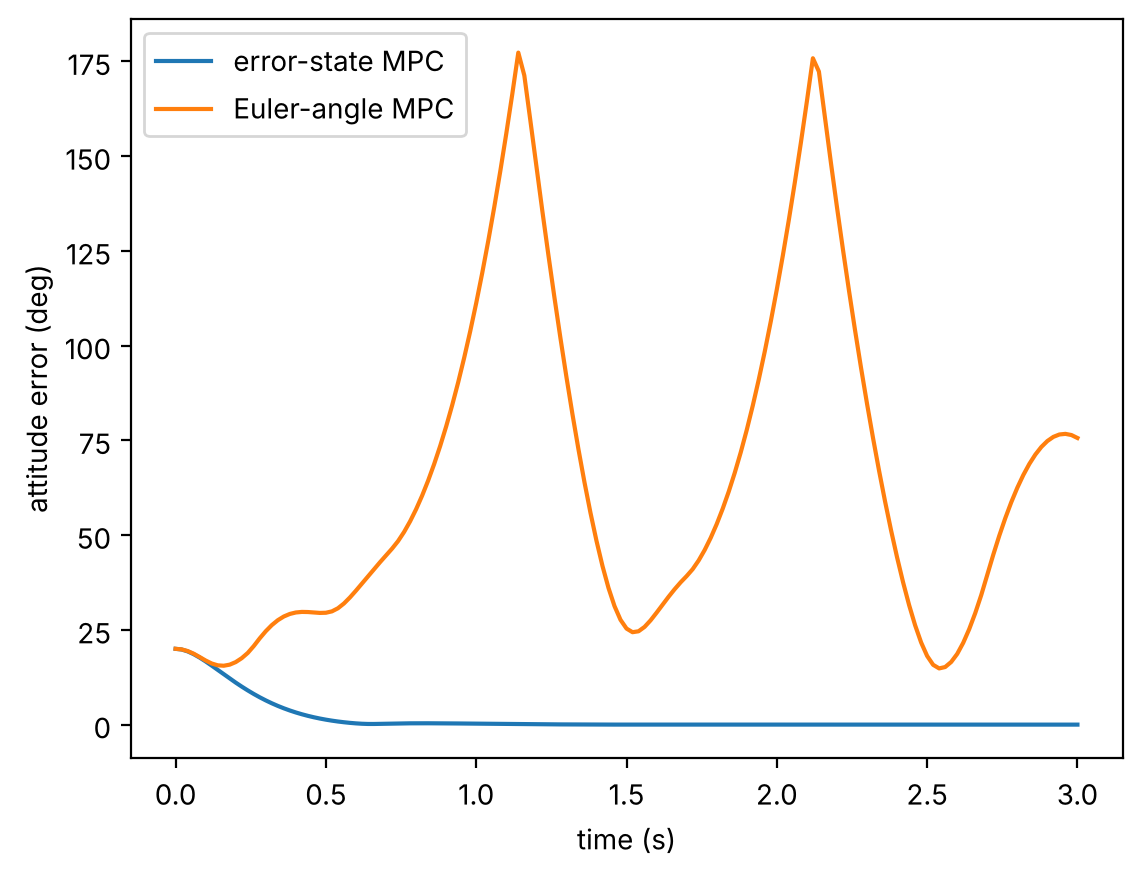

In [7]:
Rd_hold = Ry(np.radians(85.0))
hold = lambda t: (Rd_hold, ZERO3, ZERO3)
R0h = Rd_hold @ expm_so3(np.radians(20.0) * unit([1.0, 1.0, 1.0]))
for name, ctrl in (("error-state MPC", ErrorStateMPC(hold, 3.0, tau_max=TAU_MAX)), ("Euler-angle MPC", EulerMPC(hold, 3.0, tau_max=TAU_MAX))):
    r = closed_loop(ctrl, hold, R0h, ZERO3, 3.0)
    plt.plot(r["t"], r["angle"], label=name)
    print(f"{name:16s} peak error {r['angle'].max():6.1f} deg, after 3 s {r['angle'][-1]:6.2f} deg")
plt.xlabel("time (s)"); plt.ylabel("attitude error (deg)"); plt.legend(); plt.show()

## What is convex, and what is not

The QP is convex. The model inside it is first order. A pure attitude error is propagated exactly at any size. A velocity error is not.

In [8]:
def prediction_error(theta_deg, rate=2.0, t0=0.45, N=N_MPC, h=H_MPC):
    """How well the linear model predicts the error N steps ahead, with the feedforward torque alone.

    The initial error is an attitude error of angle theta and a velocity error of rate * theta.
    """
    ref = flip_ref()
    k0 = int(round(t0 / h))
    Rd, Od, _ = ref(k0 * h)
    chi0 = np.radians(theta_deg) * unit([1.0, -0.6, 0.8])
    dO0 = rate * np.radians(theta_deg) * unit([0.5, 1.0, -0.3])
    R, Om, s = Rd @ expm_so3(chi0), Od + dO0, np.r_[chi0, dO0]
    Rn, On = Rd.copy(), Od.copy()                        # the reference under the same sampled torque
    for i in range(N):
        tm = (k0 + i + 0.5) * h
        R, Om = plant_step(R, Om, ref(tm)[2], h)
        Rn, On = plant_step(Rn, On, ref(tm)[2], h)
        A, _ = zoh(err_A(ref(tm)[1]), ERR_B, h)
        s = A @ s
    true = np.r_[log_so3(Rn.T @ R), Om - On]
    return float(np.linalg.norm(s - true) / np.linalg.norm(true))


for th in (2, 10, 30, 60, 120):
    print(f"error {th:3d} deg: prediction half a second ahead is off by {100 * prediction_error(th):5.1f}% "
          f"(attitude error alone: {100 * prediction_error(th, rate=0.0):.2f}%)")

# the logarithm jumps at half a turn
Rd, Od, _ = ref(0.0)
a = unit([0.3, 1.0, 0.2])
t179 = ErrorStateMPC(ref, T_end, tau_max=TAU_MAX)(0, Rd @ expm_so3(np.radians(179.0) * a), Od)
t181 = ErrorStateMPC(ref, T_end, tau_max=TAU_MAX)(0, Rd @ expm_so3(np.radians(181.0) * a), Od)
print("first torque at 179 deg:", t179, "\nfirst torque at 181 deg:", t181)

error   2 deg: prediction half a second ahead is off by   1.5% (attitude error alone: 0.09%)


error  10 deg: prediction half a second ahead is off by   7.4% (attitude error alone: 0.09%)


error  30 deg: prediction half a second ahead is off by  21.6% (attitude error alone: 0.09%)


error  60 deg: prediction half a second ahead is off by  41.2% (attitude error alone: 0.09%)


error 120 deg: prediction half a second ahead is off by  76.1% (attitude error alone: 0.09%)
first torque at 179 deg: [-0.6 -0.6 -0.6] 
first torque at 181 deg: [0.6 0.6 0.6]


## From tracking to planning

Direct transcription of a rest-to-rest turn with torque bounds and a keep-out cone for the body axis $e_1$:

$$\min\ \tfrac{h}{2}\sum_k\|\tau_k\|^2 \quad\text{subject to}\quad \log\big(R_{k+1}^\top R_k\exp(h\,\Omega_k^\wedge)\big)^\vee = 0,\quad J(\Omega_{k+1}-\Omega_k) = h\,(J\Omega_k\times\Omega_k + \tau_k),$$

$|\tau_{k,i}| \le \tau_{\max}$ and $q_c\cdot R_k e_1 \le \cos 30^\circ$. The unknowns are rotation matrices and vectors. The steps are $(\eta_k, \delta\Omega_k, \delta\tau_k)$, applied as $R_k \leftarrow R_k\exp(\eta_k^\wedge)$. We check the Jacobians along those steps by finite differences.

In [9]:
class Reorient:
    """Minimum-effort rest-to-rest reorientation with torque bounds and a keep-out cone."""

    def __init__(self, N=20, h=0.1, R0=I3, RN=None, q_c=None, cone_deg=30.0, tau_max=0.15, J=J_B):
        self.N, self.h, self.J, self.tau_max = N, h, J, tau_max
        self.R0 = np.array(R0, float)
        self.RN = Rz(np.radians(120.0)) if RN is None else np.array(RN, float)
        self.q_c = unit([np.cos(np.radians(60.0)), np.sin(np.radians(60.0)), 0.15] if q_c is None else q_c)
        self.cos_c = np.cos(np.radians(cone_deg))
        self.cone_deg = cone_deg
        self.n = 9 * N - 6                               # tangent dimension
        self.n_eq = 6 * N
        self.n_in = 6 * N + (N - 1)

    # ---- index maps into the tangent vector -------------------------------
    def i_tau(self, k):
        return slice(9 * k, 9 * k + 3)

    def i_eta(self, k):                                  # k = 1..N-1
        return slice(9 * (k - 1) + 3, 9 * (k - 1) + 6)

    def i_dOm(self, k):                                  # k = 1..N-1
        return slice(9 * (k - 1) + 6, 9 * (k - 1) + 9)

    # ---- points -----------------------------------------------------------
    def initial_guess(self, bulge=0.0):
        """Attitudes on the geodesic from R0 to RN, optionally pushed sideways, with zero torque."""
        N, h = self.N, self.h
        phi = log_so3(self.R0.T @ self.RN)
        R = np.zeros((N + 1, 3, 3))
        for k in range(N + 1):
            sk = k / N
            side = bulge * np.sin(np.pi * sk) * unit(np.cross(phi, E1))
            R[k] = self.R0 @ expm_so3(sk * phi) @ expm_so3(side)
        R[N] = self.RN
        Om = np.zeros((N + 1, 3))
        for k in range(1, N):
            Om[k] = log_so3(R[k].T @ R[k + 1]) / h
        return dict(R=R, Om=Om, tau=np.zeros((N, 3)))

    def retract(self, x, d, alpha=1.0):
        """Move along the tangent vector d: attitudes by the exponential, the rest by addition."""
        R, Om, tau = x["R"].copy(), x["Om"].copy(), x["tau"].copy()
        for k in range(self.N):
            tau[k] += alpha * d[self.i_tau(k)]
        for k in range(1, self.N):
            R[k] = R[k] @ expm_so3(alpha * d[self.i_eta(k)])
            Om[k] += alpha * d[self.i_dOm(k)]
        return dict(R=R, Om=Om, tau=tau)

    # ---- functions --------------------------------------------------------
    def cost(self, x):
        return 0.5 * self.h * float(np.sum(x["tau"] ** 2))

    def cost_grad(self, x):
        g = np.zeros(self.n)
        for k in range(self.N):
            g[self.i_tau(k)] = self.h * x["tau"][k]
        return g

    def eq(self, x):
        N, h, J = self.N, self.h, self.J
        R, Om, tau = x["R"], x["Om"], x["tau"]
        r = np.zeros(6 * N)
        for k in range(N):
            r[6 * k:6 * k + 3] = log_so3(R[k + 1].T @ R[k] @ expm_so3(h * Om[k]))
            r[6 * k + 3:6 * k + 6] = J @ (Om[k + 1] - Om[k]) - h * (np.cross(J @ Om[k], Om[k]) + tau[k])
        return r

    def eq_jac(self, x):
        """Jacobian of the residuals with respect to the tangent vector."""
        N, h, J = self.N, self.h, self.J
        R, Om = x["R"], x["Om"]
        A = np.zeros((6 * N, self.n))
        for k in range(N):
            F = expm_so3(h * Om[k])
            rho = log_so3(R[k + 1].T @ R[k] @ F)
            Di = dexp_inv(rho)
            rows, rows_w = slice(6 * k, 6 * k + 3), slice(6 * k + 3, 6 * k + 6)
            if k >= 1:
                A[rows, self.i_eta(k)] = Di @ F.T
                A[rows, self.i_dOm(k)] = h * Di @ dexp(h * Om[k])
                A[rows_w, self.i_dOm(k)] = -J - h * (hat(J @ Om[k]) - hat(Om[k]) @ J)
            if k + 1 <= N - 1:
                A[rows, self.i_eta(k + 1)] = -dexp_inv(-rho)
                A[rows_w, self.i_dOm(k + 1)] = J
            A[rows_w, self.i_tau(k)] = -h * I3
        return A

    def ineq(self, x):
        N = self.N
        c = np.zeros(self.n_in)
        c[:3 * N] = x["tau"].ravel() - self.tau_max
        c[3 * N:6 * N] = -x["tau"].ravel() - self.tau_max
        for k in range(1, N):
            c[6 * N + k - 1] = self.q_c @ x["R"][k] @ E1 - self.cos_c
        return c

    def ineq_jac(self, x):
        N = self.N
        A = np.zeros((self.n_in, self.n))
        for k in range(N):
            for i in range(3):
                A[3 * k + i, 9 * k + i] = 1.0
                A[3 * N + 3 * k + i, 9 * k + i] = -1.0
        for k in range(1, N):
            A[6 * N + k - 1, self.i_eta(k)] = np.cross(E1, x["R"][k].T @ self.q_c)
        return A

    def lag_grad(self, x, y, z):
        return self.cost_grad(x) + self.eq_jac(x).T @ y + self.ineq_jac(x).T @ z

    def lag_hess(self, x, y, z, eps=1e-5):
        """Hessian of the Lagrangian along the retraction: the symmetrized difference of its gradient.

        The Lagrangian couples only neighboring stages, so three colors of stages suffice.
        """
        n, H = self.n, np.zeros((self.n, self.n))
        nb = self.N                                      # blocks of 9 (the last has 3)
        for color in range(3):
            for comp in range(9):
                cols = [9 * j + comp for j in range(color, nb, 3) if 9 * j + comp < n]
                if not cols:
                    continue
                d = np.zeros(n)
                d[cols] = eps
                gp = self.lag_grad(self.retract(x, d), y, z)
                gm = self.lag_grad(self.retract(x, -d), y, z)
                dg = (gp - gm) / (2 * eps)
                for col in cols:
                    j = col // 9
                    lo, hi = max(9 * (j - 1), 0), min(9 * (j + 2), n)
                    H[lo:hi, col] = dg[lo:hi]
        return 0.5 * (H + H.T)

    def boresight(self, x):
        return x["R"][:, :, 0]


prob = Reorient()
x = prob.retract(prob.initial_guess(0.3), 0.1 * rng.normal(size=prob.n))
d, e = rng.normal(size=prob.n), 1e-6
fd = (prob.eq(prob.retract(x, d, e)) - prob.eq(prob.retract(x, d, -e))) / (2 * e)
print("Jacobian of the dynamics constraints, error:", np.abs(fd - prob.eq_jac(x) @ d).max())
fd = (prob.ineq(prob.retract(x, d, e)) - prob.ineq(prob.retract(x, d, -e))) / (2 * e)
print("Jacobian of the bounds and the cone, error: ", np.abs(fd - prob.ineq_jac(x) @ d).max())

Jacobian of the dynamics constraints, error: 3.979439000545426e-11
Jacobian of the bounds and the cone, error:  8.406042528719126e-11


## Walls made of logarithms

A primal-dual interior point: slacks $w > 0$ with $c(x) + w = 0$, multipliers $y$ and $z > 0$, and Newton's method on

$$\operatorname{grad}\Phi + A_r^\top y + A_c^\top z = 0,\qquad r = 0,\qquad c + w = 0,\qquad w_i z_i = \mu,$$

with $\mu$ reduced toward zero. The primal step is applied by the retraction. Read the docstring of `interior_point` for exactly what it does and does not do.

20 iterations in 2.5 s, converged: True
cost: 0.01864390794711696  largest torque: 0.14999983158337094  closest to the cone: -2.981842565086268e-07
attitudes are rotations: 1.5543122344752192e-15


SLSQP on the shooting form, cost: 0.018643880039424843


a guess bulged the other way converges to cost 0.021606258139719215


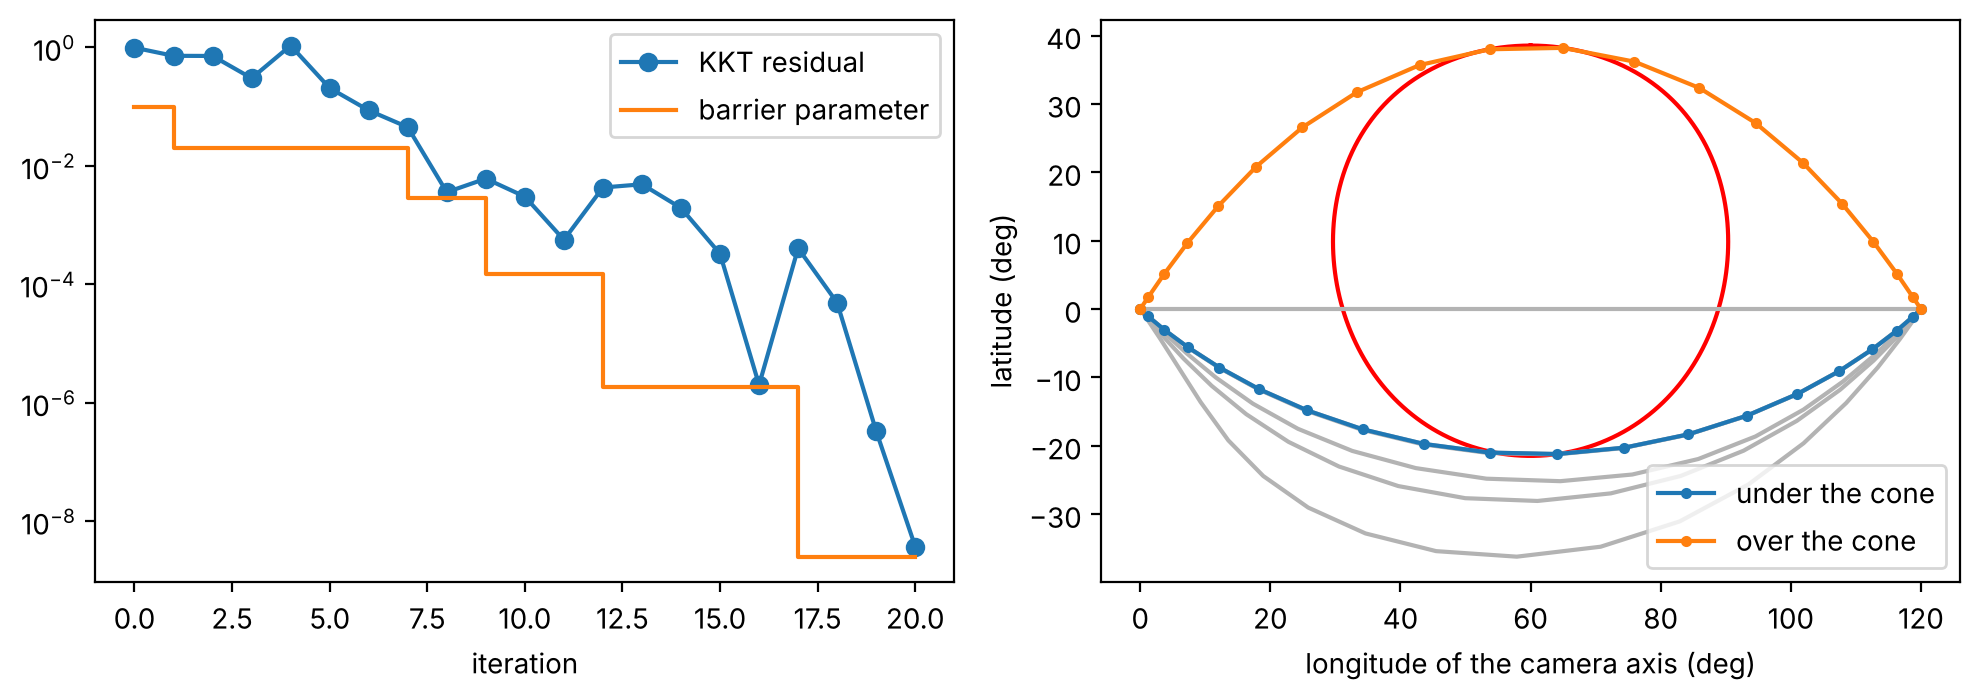

In [10]:
def kkt_error(prob, x, y, z, w, mu):
    """The four blocks of the primal-dual residual and its largest entry."""
    gL = prob.lag_grad(x, y, z)
    r, c = prob.eq(x), prob.ineq(x)
    blocks = (gL, r, c + w, w * z - mu)
    return blocks, max(float(np.max(np.abs(b))) for b in blocks)


def interior_point(prob, x0, mu0=0.1, tol=1e-8, max_iter=300, fixed_mu=None, state=None, log=None, split=True):
    """Primal-dual interior point with on-manifold primal steps.

    Unknowns: x (attitudes, velocities, torques), multipliers y of the dynamics, multipliers z >= 0
    and slacks w > 0 of the inequalities c(x) + w = 0. Each iteration solves the Newton system of
        grad Phi + A_r^T y + A_c^T z = 0,  r = 0,  c + w = 0,  w z = mu,
    shortens the step so that w and z stay positive, backtracks on the norm of that residual,
    retracts x and adds the rest. The barrier parameter mu is reduced when the residual is below
    10 mu. With ``fixed_mu`` the subproblem for that mu alone is solved (a point of the central path).
    """
    x = x0
    mu = mu0 if fixed_mu is None else fixed_mu
    if state is None:
        y = np.zeros(prob.n_eq)
        w = np.maximum(-prob.ineq(x), 0.05)
        z = mu / w
    else:
        y, z, w = (np.array(v, float) for v in state)
    hist = []
    for it in range(max_iter):
        blocks, E_mu = kkt_error(prob, x, y, z, w, mu)
        E_0 = max(float(np.max(np.abs(b))) for b in (blocks[0], blocks[1], blocks[2], w * z))
        hist.append(dict(E0=E_0, Emu=E_mu, mu=mu, cost=prob.cost(x), alpha=np.nan))
        if log is not None:
            log(it, x, mu)
        if fixed_mu is None:
            if E_0 <= tol:
                break
            if E_mu <= 10 * mu and mu > tol / 10:
                mu = max(tol / 10, min(0.2 * mu, mu**1.5))
                blocks, E_mu = kkt_error(prob, x, y, z, w, mu)
        elif E_mu <= tol:
            break
        gL, r, cw, comp = blocks
        Ar, Ac = prob.eq_jac(x), prob.ineq_jac(x)
        H = prob.lag_hess(x, y, z)
        Sig = z / w
        K = np.zeros((prob.n + prob.n_eq, prob.n + prob.n_eq))
        Hbar = H + Ac.T @ (Sig[:, None] * Ac)
        K[:prob.n, prob.n:], K[prob.n:, :prob.n] = Ar.T, Ar
        rhs = -np.r_[gL + Ac.T @ (Sig * cw - comp / w), r]
        delta = 0.0
        while True:                                      # inertia correction: n positive, n_eq negative
            K[:prob.n, :prob.n] = Hbar + delta * np.eye(prob.n)
            ev = np.linalg.eigvalsh(K)
            if np.sum(ev > 0) == prob.n and np.sum(ev < 0) == prob.n_eq:
                break
            delta = 1e-4 if delta == 0.0 else 10 * delta
        sol = np.linalg.solve(K, rhs)
        dx, dy = sol[:prob.n], sol[prob.n:]
        dw = -cw - Ac @ dx
        dz = -comp / w - Sig * dw
        frac = max(0.99, 1 - mu)
        a, az = 1.0, 1.0                                 # primal step for (x, w, y), dual step for z
        if np.any(dw < 0):
            a = min(1.0, float(np.min(-frac * w[dw < 0] / dw[dw < 0])))
        if np.any(dz < 0):
            az = min(1.0, float(np.min(-frac * z[dz < 0] / dz[dz < 0])))
        if not split:
            a = az = min(a, az)
        psi0 = np.sqrt(sum(float(b @ b) for b in blocks))
        for _ in range(30):
            xn, yn, zn, wn = prob.retract(x, dx, a), y + a * dy, z + az * dz, w + a * dw
            bn, _ = kkt_error(prob, xn, yn, zn, wn, mu)
            if np.sqrt(sum(float(b @ b) for b in bn)) <= (1 - 1e-4 * a) * psi0 or delta > 0:
                break
            a *= 0.5
            az = a if not split else az
        x, y, z, w = xn, yn, zn, wn
        hist[-1]["alpha"], hist[-1]["delta"] = a, delta
    return dict(x=x, y=y, z=z, w=w, mu=mu, hist=hist, iters=len(hist) - 1,
                converged=(hist[-1]["E0"] <= tol) if fixed_mu is None else (hist[-1]["Emu"] <= tol))


def central_path(prob, x0, mus):
    """Solve the barrier problem for each mu in turn, each started from the previous one."""
    out, state, x = [], None, x0
    for mu in mus:
        if state is not None:                            # keep w z near the new mu
            state = (state[0], mu / state[2], state[2])
        res = interior_point(prob, x, fixed_mu=mu, tol=1e-9, state=state)
        x, state = res["x"], (res["y"], res["z"], res["w"])
        out.append(res)
    return out


def rollout(prob, taus):
    """Shooting: the discrete dynamics applied to a torque sequence."""
    R, Om = [prob.R0], [np.zeros(3)]
    for k in range(prob.N):
        R.append(R[-1] @ expm_so3(prob.h * Om[-1]))
        Om.append(Om[-1] + prob.h * np.linalg.solve(prob.J, np.cross(prob.J @ Om[-1], Om[-1]) + taus[k]))
    return np.array(R), np.array(Om)


def shooting_check(prob, tau0):
    """The same problem in the torques alone, solved by SciPy's SLSQP from tau0."""
    N = prob.N

    def term(u):
        R, Om = rollout(prob, u.reshape(N, 3))
        return np.r_[log_so3(prob.RN.T @ R[-1]), Om[-1]]

    def cone(u):
        R, _ = rollout(prob, u.reshape(N, 3))
        return prob.cos_c - R[1:N, :, 0] @ prob.q_c

    res = minimize(lambda u: 0.5 * prob.h * u @ u, tau0.ravel(), jac=lambda u: prob.h * u, method="SLSQP",
                   bounds=[(-prob.tau_max, prob.tau_max)] * (3 * N),
                   constraints=[dict(type="eq", fun=term), dict(type="ineq", fun=cone)],
                   options=dict(maxiter=500, ftol=1e-13))
    return res


snaps = []
t0 = time.perf_counter()
sol = interior_point(prob, prob.initial_guess(0.0), log=lambda it, x, mu: snaps.append(x["R"][:, :, 0].copy()))
xs = sol["x"]
print(f"{sol['iters']} iterations in {time.perf_counter() - t0:.1f} s, converged: {sol['converged']}")
print("cost:", prob.cost(xs), " largest torque:", np.abs(xs["tau"]).max(), " closest to the cone:", prob.ineq(xs)[6 * prob.N:].max())
print("attitudes are rotations:", np.abs(np.einsum("kij,kil->kjl", xs["R"], xs["R"]) - I3).max())
chk = shooting_check(prob, xs["tau"] + 0.01 * rng.normal(size=xs["tau"].shape))
print("SLSQP on the shooting form, cost:", chk.fun)

over = interior_point(prob, prob.initial_guess(-0.3))
print("a guess bulged the other way converges to cost", prob.cost(over["x"]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].semilogy([hh["E0"] for hh in sol["hist"]], "-o", label="KKT residual")
ax[0].semilogy([hh["mu"] for hh in sol["hist"]], drawstyle="steps-post", label="barrier parameter")
ax[0].set_xlabel("iteration"); ax[0].legend()
# the camera axis in longitude and latitude, with the cone
lonlat = lambda P: (np.degrees(np.arctan2(P[:, 1], P[:, 0])), np.degrees(np.arcsin(P[:, 2])))
cone = np.array([expm_so3(a_ * prob.q_c) @ expm_so3(np.radians(prob.cone_deg) * unit(np.cross(prob.q_c, E3))) @ prob.q_c
                 for a_ in np.linspace(0, 2 * np.pi, 200)])
ax[1].plot(*lonlat(cone), "r")
for P in snaps[::4]:
    ax[1].plot(*lonlat(P), color="0.7")
ax[1].plot(*lonlat(xs["R"][:, :, 0]), "-o", ms=3, label="under the cone")
ax[1].plot(*lonlat(over["x"]["R"][:, :, 0]), "-o", ms=3, label="over the cone")
ax[1].set(xlabel="longitude of the camera axis (deg)", ylabel="latitude (deg)"); ax[1].legend()
plt.tight_layout(); plt.show()

## Starting points for the exercises

- **Mean on the sphere.** Change `pts` so that one reading is 150° from the others and run `s2_mean_newton`. Print the eigenvalues of the Hessian on the tangent plane at each iterate.
- **Hessian and gradient.** Difference `so3_mean_grad` to get the derivative of the gradient at a point away from the minimum, and compare its symmetric part with `so3_mean_hess`.
- **Terminal weight.** In `ErrorStateMPC`, replace `self.Pf` by a zero matrix and shorten `N` until the flip is lost.
- **The bound.** Loop the closed-loop cell over `TAU_MAX` from 0.8 down to 0.4 and plot the worst error of the three controllers.
- **Central path.** Call `central_path(prob, prob.initial_guess(-0.3), [1e-2, 1e-3, 1e-4, 1e-5, 1e-6])` and plot the cost of each point. Move `q_c` with `Reorient(q_c=[...])` until the two minima cost the same.

In [11]:
path = central_path(prob, prob.initial_guess(0.0), [1e-2, 1e-3, 1e-4, 1e-5, 1e-6])
for p_, mu in zip(path, [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]):
    margin = np.degrees(np.arccos(prob.ineq(p_["x"])[6 * prob.N:].max() + prob.cos_c)) - prob.cone_deg
    print(f"mu = {mu:.0e}: cost {prob.cost(p_['x']):.5f}, margin to the cone {margin:.3f} deg")

mu = 1e-02: cost 0.02387, margin to the cone 14.457 deg
mu = 1e-03: cost 0.02256, margin to the cone 12.774 deg
mu = 1e-04: cost 0.01977, margin to the cone 4.747 deg
mu = 1e-05: cost 0.01876, margin to the cone 0.230 deg
mu = 1e-06: cost 0.01866, margin to the cone 0.015 deg
